# SMS Spam Classification using Support Vector Machine (SVM)

**Project goal:** Build a machine-learning model that classifies SMS messages as **Spam** or **Ham (legitimate)**.

**Dataset:** SMS Spam Collection (UCI Machine Learning Repository / Kaggle mirror)  
https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset

**Pipeline overview**

`Raw SMS → Data Cleaning → Text Preprocessing → TF-IDF → SVM → Hyperparameter Tuning → Evaluation → Save Model → Custom Prediction`

---

## Key Features

This notebook builds an end-to-end SMS spam classifier using **TF-IDF feature extraction** and a **Linear Support Vector Machine**. Every stage — from raw text to a deployable model — is implemented, explained, and evaluated.

### Reproducibility
- Fixed random seeds (`RANDOM_STATE = 42`) ensure every run gives identical results.
- Central configuration block keeps tunable parameters in one place.

### Environment-independent data loading
- Universal loader that works in Jupyter, VS Code, Google Colab, or plain Python.
- Checks for local files first, then auto-downloads from the UCI repository, and only falls back to manual upload as a last resort.
- No hard dependency on Google Colab — the notebook runs anywhere.

### Data quality and exploration
- Automated checks for missing values, duplicate rows, and duplicate messages.
- Class-imbalance analysis (~87% ham / 13% spam) with count plots and histograms.
- Word clouds comparing spam and ham vocabulary side by side.

### Careful text preprocessing
- Lower-casing, URL/email/digit removal, punctuation stripping.
- **Negation-aware stop-word removal** — words like `not`, `never`, and `dont` are preserved so that *"you have not won"* is not collapsed into *"you have won"*.
- Lemmatization and filtering of 1-character tokens.
- Pre-compiled regex patterns for fast repeated application.

### Model selection with baselines
- Three algorithms compared on the training set with 5-fold cross-validation: **Multinomial Naive Bayes**, **Logistic Regression**, and **LinearSVC**.
- F1-score on the minority (spam) class used as the deciding metric — not accuracy.

### Full-pipeline hyperparameter tuning
- `GridSearchCV` tunes both the vectorizer (`max_features`, `ngram_range`, `sublinear_tf`) and the classifier (`C`).
- Tuning performed on the training set only; the test set is used once for a final unbiased evaluation.

### Comprehensive evaluation
- Accuracy, precision, recall, and F1 scores.
- Full classification report.
- Confusion matrix with true-positive / false-positive / false-negative breakdown.
- ROC curve with AUC.
- Precision-Recall curve with average precision (more informative than ROC on imbalanced data).

### Interpretability
- The SVM's learned coefficients are ranked to reveal which TF-IDF features push a message towards spam or ham.
- Plots show the top 15 features for each class.

### Reusability
- The full pipeline (vectorizer + classifier) is saved to disk with `joblib`.
- A `predict_sms()` helper applies the exact same preprocessing used during training to classify new messages and returns a decision score.

### Deliverables
- `SMS_Spam_SVM.ipynb` — the notebook itself.
- `requirements.txt` — one-command installation of dependencies.
- `.gitignore` — excludes generated artefacts from version control.
- `README.md` — project overview, results table, setup instructions, and methodology.

---

**Result:** ~98% test accuracy and ~0.94 F1 on the spam class, with the full pipeline reproducible from a single `Run All`.

In [89]:
import io, os, re, random, string, warnings, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import (
    train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

import joblib
import sklearn

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_DIR = Path("data")
MODEL_DIR = Path("models")
MODEL_PATH = MODEL_DIR / "sms_spam_svm.joblib"

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"nltk         : {nltk.__version__}")
print(f"joblib       : {joblib.__version__}")
print("Libraries loaded successfully.")

pandas       : 3.0.6
numpy        : 2.5.4
scikit-learn : 1.9.1
nltk         : 3.10.3
joblib       : 1.6.0
Libraries loaded successfully.


## 1. Load the Dataset

The loader tries local files first, then auto-downloads from UCI, then falls back to the interactive Colab upload.

In [90]:
KAGGLE_CSV = DATA_DIR / "spam.csv"
UCI_TXT = DATA_DIR / "SMSSpamCollection"
CACHED_CSV = DATA_DIR / "sms_spam.csv"
UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"


def load_sms_data(verbose=True):
    DATA_DIR.mkdir(exist_ok=True)
    if KAGGLE_CSV.exists():
        df = pd.read_csv(KAGGLE_CSV, encoding="latin-1")[["v1", "v2"]]
        df.columns = ["label", "message"]
        if verbose: print(f"Loaded Kaggle mirror from {KAGGLE_CSV}")
        return df
    if UCI_TXT.exists():
        df = pd.read_csv(UCI_TXT, sep="\t", header=None, names=["label", "message"])
        if verbose: print(f"Loaded UCI file from {UCI_TXT}")
        return df
    if CACHED_CSV.exists():
        df = pd.read_csv(CACHED_CSV)
        if verbose: print(f"Loaded cached copy from {CACHED_CSV}")
        return df
    try:
        if verbose: print("Downloading SMS Spam Collection from UCI ...")
        with urllib.request.urlopen(UCI_URL, timeout=60) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
            member = next(n for n in archive.namelist() if "SMSSpamCollection" in n)
            with archive.open(member) as handle:
                df = pd.read_csv(handle, sep="\t", header=None, names=["label", "message"])
        df.to_csv(CACHED_CSV, index=False)
        if verbose: print(f"Download complete, cached at {CACHED_CSV}")
        return df
    except Exception as exc:
        try:
            from google.colab import files
            print("Automatic download failed. Falling back to manual upload.")
            uploaded = files.upload()
            fname = next(iter(uploaded))
            df = pd.read_csv(fname, encoding="latin-1")
            if {"v1", "v2"}.issubset(df.columns):
                df = df[["v1", "v2"]]
                df.columns = ["label", "message"]
            return df
        except Exception:
            raise RuntimeError("Could not obtain the dataset automatically.") from exc


df = load_sms_data()
print(f"\nShape: {df.shape}")
df.head()

Loaded cached copy from data\sms_spam.csv

Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Data Quality Check

In [91]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows      :", df.duplicated().sum())
print("Duplicate messages  :", df.duplicated(subset="message").sum())
print("\nClass distribution:")
print(df["label"].value_counts())
print("\nClass percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Duplicate rows      : 403
Duplicate messages  : 403

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [92]:
df = df.dropna(subset=["label", "message"]).drop_duplicates().reset_index(drop=True)
print("Shape after cleaning:", df.shape)
print("\nUpdated class distribution:")
print(df["label"].value_counts())

Shape after cleaning: (5169, 2)

Updated class distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA)

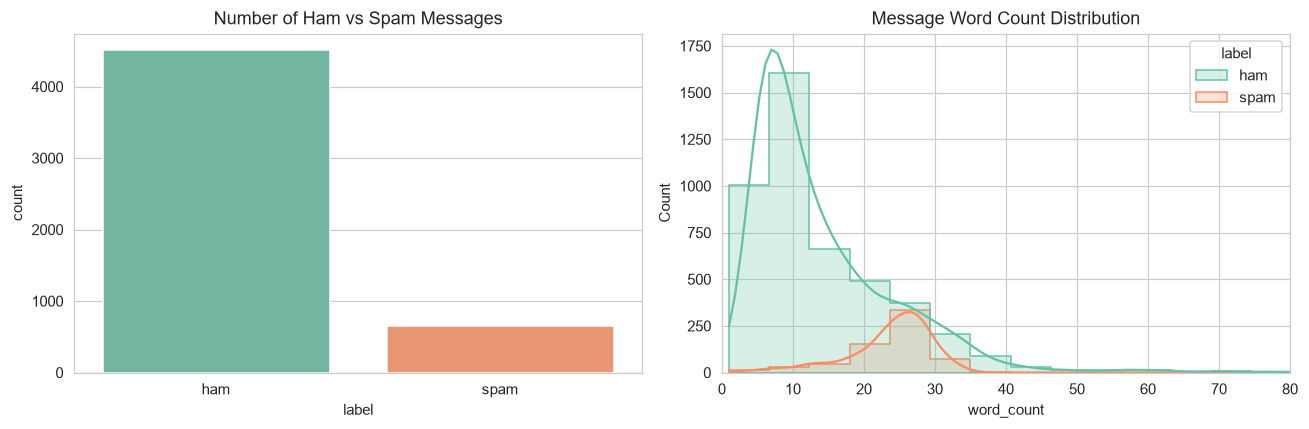

Average word count by class:
label
ham     14.24
spam    23.74
Name: word_count, dtype: float64


In [93]:
df["char_count"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="label", ax=axes[0], palette="Set2")
axes[0].set_title("Number of Ham vs Spam Messages")
sns.histplot(data=df, x="word_count", hue="label", bins=30, kde=True,
             element="step", ax=axes[1], palette="Set2")
axes[1].set_title("Message Word Count Distribution")
axes[1].set_xlim(0, 80)
plt.tight_layout()
plt.show()

print("Average word count by class:")
print(df.groupby("label")["word_count"].mean().round(2))

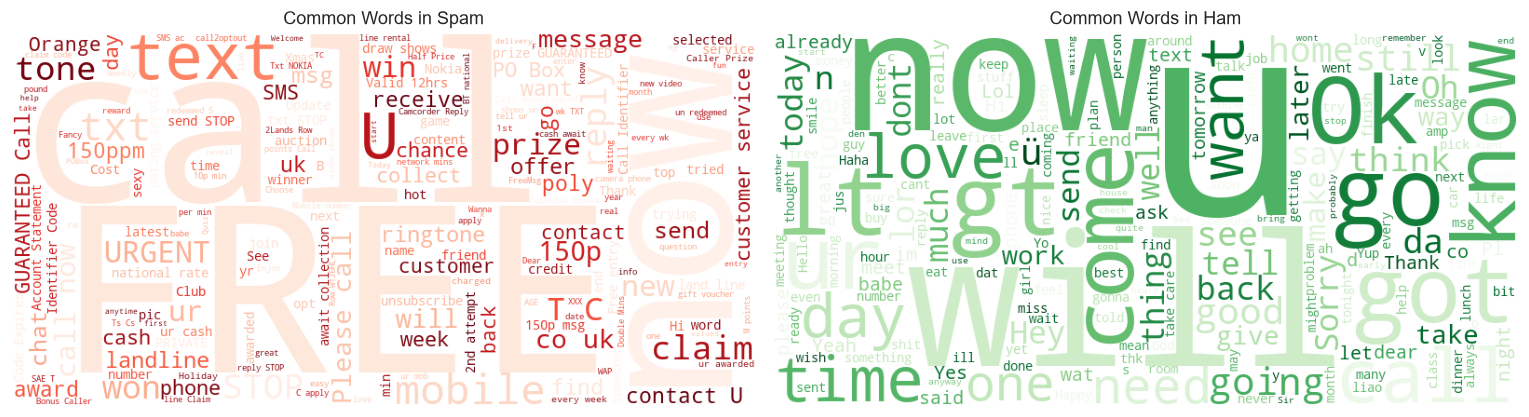

In [94]:
spam_text = " ".join(df.loc[df["label"] == "spam", "message"])
ham_text = " ".join(df.loc[df["label"] == "ham", "message"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, text, title, colour in [
    (axes[0], spam_text, "Common Words in Spam", "Reds"),
    (axes[1], ham_text, "Common Words in Ham", "Greens"),
]:
    cloud = WordCloud(background_color="white", width=800, height=400,
                      colormap=colour, random_state=RANDOM_STATE).generate(text)
    ax.imshow(cloud)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Text Preprocessing

Negation words are preserved, so *"you have not won"* is not simplified to *"you have won"*.

In [95]:
NEGATIONS = {
    "no", "not", "nor", "never", "none", "cannot",
    "dont", "cant", "wont", "isnt", "arent", "wasnt", "werent",
    "doesnt", "didnt", "havent", "hasnt", "hadnt",
    "shouldnt", "wouldnt", "couldnt", "mustnt", "neednt",
}
stop_words = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()

URL_RE = re.compile(r"http\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+")
NUM_RE = re.compile(r"\d+")
NON_ALPHA_RE = re.compile(r"[^a-z\s]")
MULTISPACE_RE = re.compile(r"\s+")
PUNCT_TABLE = str.maketrans("", "", string.punctuation)


def clean_text(text):
    text = str(text).lower()
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    text = NUM_RE.sub(" ", text)
    text = text.translate(PUNCT_TABLE)
    text = NON_ALPHA_RE.sub(" ", text)
    tokens = [
        lemmatizer.lemmatize(word)
        for word in text.split()
        if word not in stop_words and len(word) > 1
    ]
    return MULTISPACE_RE.sub(" ", " ".join(tokens)).strip()


df["clean_message"] = df["message"].apply(clean_text)
before = len(df)
df = df.loc[df["clean_message"].str.strip() != ""].reset_index(drop=True)
print(f"Dropped {before - len(df)} row(s) that became empty after cleaning.")
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
print(f"\nFinal dataset size: {df.shape}")
df[["label", "message", "clean_message"]].head()

Dropped 7 row(s) that became empty after cleaning.

Final dataset size: (5162, 6)


,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis great wo...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,dun say early hor already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though


## 5. Train/Test Split

In [96]:
X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Training samples: {len(X_train):,}  |  spam share = {y_train.mean():.3%}")
print(f"Testing samples : {len(X_test):,}  |  spam share = {y_test.mean():.3%}")

Training samples: 4,129  |  spam share = 12.642%
Testing samples : 1,033  |  spam share = 12.682%


## 6. Baseline Model Comparison

Naive Bayes vs Logistic Regression vs LinearSVC, scored on F1.

In [97]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "MultinomialNB": MultinomialNB(),
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "LinearSVC": LinearSVC(random_state=RANDOM_STATE),
}

rows = []
for name, clf in candidates.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", clf),
    ])
    acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    rows.append({"Model": name, "CV accuracy": acc.mean(),
                 "CV F1 (spam)": f1.mean(), "F1 std": f1.std()})

baseline_df = pd.DataFrame(rows).sort_values("CV F1 (spam)", ascending=False).reset_index(drop=True)
baseline_df.round(4)

,Model,CV accuracy,CV F1 (spam),F1 std
0,LinearSVC,0.9782,0.9080,0.0142
1,MultinomialNB,0.9629,0.8284,0.0217
2,LogisticRegression,0.9562,0.7919,0.0300


## 7. Hyperparameter Tuning

In [98]:
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("svm", LinearSVC(random_state=RANDOM_STATE)),
])

param_grid = {
    "tfidf__max_features": [5000, None],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__sublinear_tf": [True],
    "svm__C": [0.1, 0.5, 1, 2, 5, 10],
}

grid = GridSearchCV(svm_pipeline, param_grid, cv=cv, scoring="f1", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("\nBest Parameters :", grid.best_params_)
print(f"Best 5-Fold CV F1: {grid.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Parameters : {'svm__C': 2, 'tfidf__max_features': None, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}
Best 5-Fold CV F1: 0.9083


In [99]:
model = grid.best_estimator_
pred = model.predict(X_test)
decision_scores = model.decision_function(X_test)

print("Tuned SVM Results (held-out test set)")
print("-" * 40)
print(f"Accuracy : {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred):.4f}")
print(f"Recall   : {recall_score(y_test, pred):.4f}")
print(f"F1-score : {f1_score(y_test, pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, pred, target_names=["Ham", "Spam"], digits=4))

Tuned SVM Results (held-out test set)
----------------------------------------
Accuracy : 0.9874
Precision: 0.9758
Recall   : 0.9237
F1-score : 0.9490

Classification Report:
              precision    recall  f1-score   support

         Ham     0.9890    0.9967    0.9928       902
        Spam     0.9758    0.9237    0.9490       131

    accuracy                         0.9874      1033
   macro avg     0.9824    0.9602    0.9709      1033
weighted avg     0.9873    0.9874    0.9873      1033



## 8. Confusion Matrix

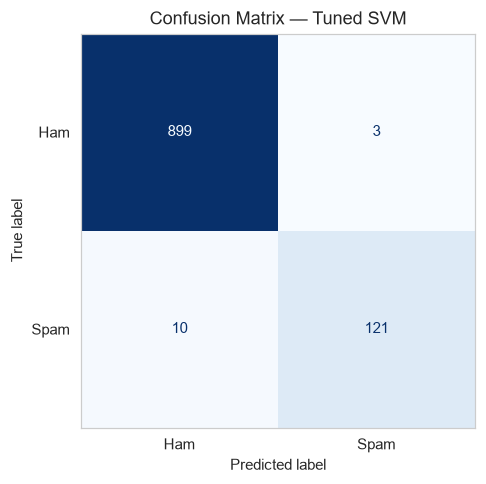

True negatives  (ham  -> ham ) : 899
False positives (ham  -> spam) : 3
False negatives (spam -> ham ) : 10
True positives  (spam -> spam) : 121


In [100]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
disp.plot(values_format="d", cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix — Tuned SVM")
ax.grid(False)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives  (ham  -> ham ) : {tn}")
print(f"False positives (ham  -> spam) : {fp}")
print(f"False negatives (spam -> ham ) : {fn}")
print(f"True positives  (spam -> spam) : {tp}")

## 9. ROC Curve, AUC and Precision-Recall

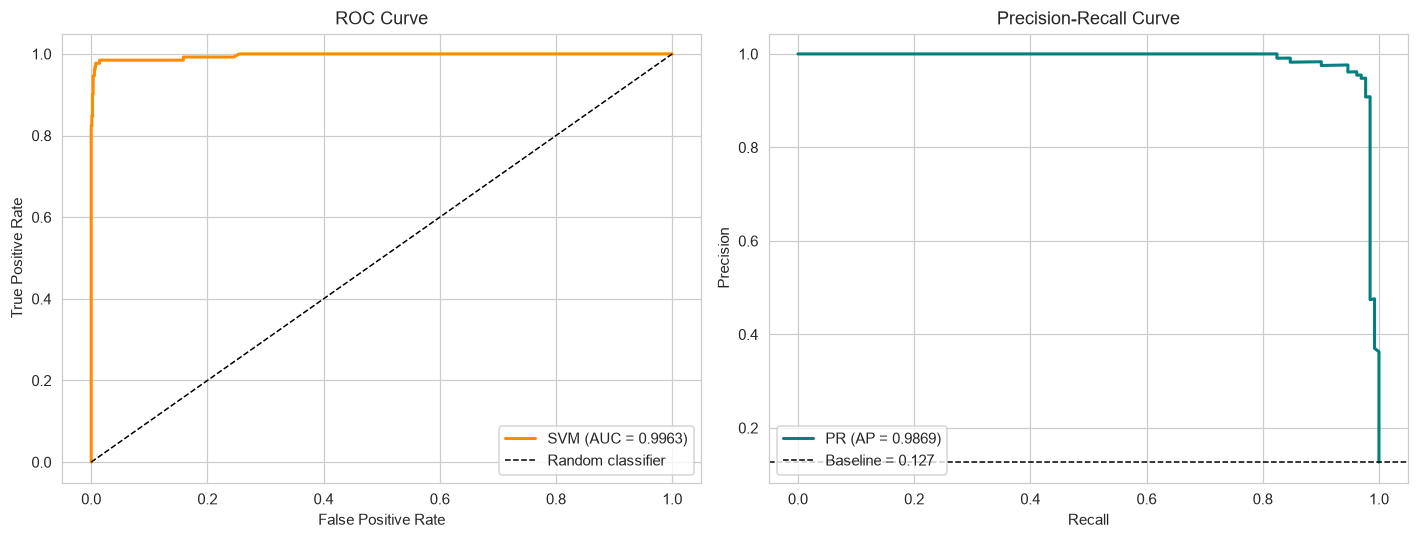

ROC-AUC               : 0.9963
Average precision (PR): 0.9869


In [101]:
fpr, tpr, _ = roc_curve(y_test, decision_scores)
auc_score = roc_auc_score(y_test, decision_scores)
prec, rec, _ = precision_recall_curve(y_test, decision_scores)
ap = average_precision_score(y_test, decision_scores)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, color="darkorange", lw=2, label=f"SVM (AUC = {auc_score:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random classifier")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, color="teal", lw=2, label=f"PR (AP = {ap:.4f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Baseline = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

print(f"ROC-AUC               : {auc_score:.4f}")
print(f"Average precision (PR): {ap:.4f}")

## 10. Cross-Validation of the Tuned Pipeline

In [102]:
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
print("5-Fold F1-scores  :", np.round(cv_scores, 4))
print(f"Mean F1-score     : {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

5-Fold F1-scores  : [0.902  0.9072 0.8958 0.8969 0.9394]
Mean F1-score     : 0.9083
Standard deviation: 0.0161


## 11. Most Informative Words

In [103]:
vectorizer = model.named_steps["tfidf"]
svm = model.named_steps["svm"]
feature_names = np.asarray(vectorizer.get_feature_names_out())
coefficients = svm.coef_[0]
order = np.argsort(coefficients)

top_spam = [(feature_names[i], coefficients[i]) for i in order[-15:][::-1]]
top_ham = [(feature_names[i], coefficients[i]) for i in order[:15]]

print("Top features associated with SPAM:")
print([w for w, _ in top_spam])
print("\nTop features associated with HAM:")
print([w for w, _ in top_ham])

Top features associated with SPAM:
['txt', 'claim', 'service', 'mobile', 'wining', 'reply', 'urgent', 'prize', 'text', 'sexy', 'tf', 'stop', 'freephone', 'pobox', 'information']

Top features associated with HAM:
['liked', 'ltgt', 'ill', 'yup', 'mail', 'said', 'sir', 'way', 'ok', 'hey', 'morning', 'later', 'plan', 'say', 'pa']


## 12. Save the Model

In [104]:
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(model, MODEL_PATH)
print(f"Model saved to {MODEL_PATH.resolve()} ({MODEL_PATH.stat().st_size / 1024:.1f} KB)")
reloaded = joblib.load(MODEL_PATH)
assert np.array_equal(reloaded.predict(X_test), pred)
print("Reloaded model reproduces the test predictions exactly.")

Model saved to C:\Users\User\Documents\sms-spam-svm\models\sms_spam_svm.joblib (190.3 KB)
Reloaded model reproduces the test predictions exactly.


## 13. Custom SMS Prediction

In [105]:
def predict_sms(text, model=None):
    if model is None:
        model = globals().get("model") or joblib.load(MODEL_PATH)
    cleaned = clean_text(text)
    prediction = model.predict([cleaned])[0]
    score = float(model.decision_function([cleaned])[0])
    return {"label": "Spam" if prediction == 1 else "Ham",
            "score": round(score, 4), "cleaned": cleaned}


test_messages = [
    "Congratulations! You have won a free iPhone. Click here now to claim your prize!",
    "URGENT! You have won a cash prize. Call 09061701461 now to claim your reward.",
    "Hi, are we still meeting tomorrow at 3 PM?",
    "Ok lar... Joking wif u oni...",
    "Please remember to bring the documents to the office on Monday.",
]

for message in test_messages:
    r = predict_sms(message)
    print(f"[{r['label']:>4}]  score = {r['score']:>7.4f}  |  {message[:60]}")


[Spam]  score =  1.0552  |  Congratulations! You have won a free iPhone. Click here now 
[Spam]  score =  2.2128  |  URGENT! You have won a cash prize. Call 09061701461 now to c
[ Ham]  score = -0.9113  |  Hi, are we still meeting tomorrow at 3 PM?
[ Ham]  score = -1.3742  |  Ok lar... Joking wif u oni...
[ Ham]  score = -1.3435  |  Please remember to bring the documents to the office on Mond


In [ ]:
# Interactive prediction loop — keeps asking until you type "quit" or "exit"
print("Type an SMS message and press Enter to classify it.")
print("Type 'quit' or 'exit' (or leave blank) to stop.\n")

while True:
    user_message = input("SMS > ").strip()

    # Exit conditions
    if not user_message or user_message.lower() in {"quit", "exit", "q"}:
        print("Stopped.")
        break

    result = predict_sms(user_message)
    print(f"  Cleaned    : {result['cleaned']}")
    print(f"  Prediction : {result['label']}")
    print(f"  Score      : {result['score']:.4f}  "
          f"({'spam-like' if result['score'] > 0 else 'ham-like'})")
    print()

Type an SMS message and press Enter to classify it.
Type 'quit' or 'exit' (or leave blank) to stop.



SMS >  not won prize sorry


  Cleaned    : not prize sorry
  Prediction : Ham
  Score      : -0.0778  (ham-like)



SMS >  404 error


  Cleaned    : error
  Prediction : Ham
  Score      : -0.7705  (ham-like)



...

  Cleaned    : prize
  Prediction : Spam
  Score      : 0.6868  (spam-like)



SMS >  give mea a prize, will you


  Cleaned    : give mea prize
  Prediction : Spam
  Score      : 0.2080  (spam-like)



SMS >  do u know, we won the prizemoney


  Cleaned    : know prizemoney
  Prediction : Ham
  Score      : -1.0343  (ham-like)

